In [1]:
import os
import sys
import json
import subprocess
from pathlib import Path
import torch
from pytorchexample.task import load_data

# Find Assignment starting from the notebook's working directory.
cwd = Path.cwd().resolve()
ASSIGNMENT_DIR = next((p for p in (cwd, *cwd.parents) if p.name == "Assignment"), None)
if ASSIGNMENT_DIR is None:
    raise RuntimeError(f"Could not find 'Assignment' above Jupyter cwd: {cwd}")

PROJECT = ASSIGNMENT_DIR / "Part_2-Federated Learning" / "quickstart-pytorch"
RESULTS_DIR = ASSIGNMENT_DIR / "Part_2-Federated Learning" / "resultat"
MODELS_DIR = ASSIGNMENT_DIR / "Part_2-Federated Learning" / "modeller"
LOGS_DIR = ASSIGNMENT_DIR / "Part_2-Federated Learning" / "logs"
FLWR = Path(sys.prefix) / ("Scripts/flwr.exe" if os.name == "nt" else "bin/flwr")




trainloader, testloader = load_data(
    partition_id=0,
    num_partitions=5,
    batch_size=32
)



NUM_ROUNDS = 35
ATTACKER_COUNTS = (0, 1, 2)

if not (PROJECT / "pyproject.toml").is_file():
    raise FileNotFoundError(f"Flower project not found: {PROJECT}")

sys.path.insert(0, str(PROJECT))
from pytorchexample.task import Net, load_data

# FedAvg: {0: Net(), 1: Net(), 2: Net()}
models_unprotected = {
    "0-attacker": None,
    "1-attacker": None,
    "2-attacker": None,
    "3-attacker": None,
}

# FedMedian
models_protected = {
    "0-attacker": None,
    "1-attacker": None,
    "2-attacker": None,
    "3-attacker": None,
}

results_unprotected = {}  # FedAvg JSON per round
results_protected = {}    # FedMedian JSON per round

print("Flower project:", PROJECT)
print("Models:", MODELS_DIR)
print("JSON:", RESULTS_DIR)
print("Flower executable:", FLWR)

c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\.venv311_AI_security\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Flower project: C:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\Part_2-Federated Learning\quickstart-pytorch
Models: C:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\Part_2-Federated Learning\modeller
JSON: C:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\Part_2-Federated Learning\resultat
Flower executable: c:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\.venv311_AI_security\Scripts\flwr.exe


In [2]:
def experiment_name(attackers: int, aggregation: str = "fedavg") -> str:
    return f"{aggregation}_attack{attackers}_rounds{NUM_ROUNDS}"


# def load_model(path: Path):
#     """Load global PyTorch weights saved from Flower's final ArrayRecord."""
#     model = Net()
#     model.load_state_dict(torch.load(path, map_location="cpu", weights_only=True))
#     model.eval()
#     return model



def load_model(aggregation: str, attackers: int):
    """Load an existing trained model and its JSON results."""

    name = experiment_name(attackers, aggregation)

    model_path = MODELS_DIR / f"{name}.pt"
    metrics_path = RESULTS_DIR / f"{name}.json"

    # if not model_path.is_file():
    #     raise FileNotFoundError(f"Model not found: {model_path}")

    # if not metrics_path.is_file():
    #     raise FileNotFoundError(f"Results not found: {metrics_path}")

    # model = load_model(model_path)
    model = Net()
    model.load_state_dict(torch.load(model_path, map_location="cpu", weights_only=True))
    model.eval()


    metrics = json.loads(metrics_path.read_text(encoding="utf-8"))

    print(f"Loaded: {name}")

    return model, metrics


def train_model(aggregation: str, attackers: int):
    """Train one experiment, then load its saved model and results."""

    run_flower(aggregation, attackers)

    return load_model(aggregation, attackers)


# Run flower
def run_flower(aggregation: str, attackers: int):
    """Run one experiment synchronously; keep Flower output in a log file."""
    if not FLWR.is_file():
        raise FileNotFoundError(f"Flower CLI is not available in this Jupyter kernel: {FLWR}")

    LOGS_DIR.mkdir(parents=True, exist_ok=True)
    name = experiment_name(attackers, aggregation)
    log_path = LOGS_DIR / f"{name}.log"

    # # Strings in Flower run-config must have TOML-style quotes.
    # config = (
    #     f'num-server-rounds={NUM_ROUNDS} '
    #     f'num-attacked-clients={attackers} '
    #     f'use-median={str(strategy == "fedmedian").lower()} '
    #     f'save-model=true '
    #     f'run-name="{strategy}"'
    # )

    config = (
        f'num-server-rounds={NUM_ROUNDS} '
        f'num-attacked-clients={attackers} '
        f'use-median={str(aggregation == "fedmedian").lower()} '
        f'save-model=true '
        # f'run-name="{name}"'
        f'run-name="{aggregation}"'
    )

    env = os.environ.copy()
    env["FLWR_HOME"] = str(Path.home() / ".flwr_dv2607_terminal")
    env["FLWR_LOCAL_SUPERLINK_HTTP_API_PORT"] = "39125"
    env["FLWR_DISABLE_RUNTIME_DEPENDENCY_INSTALLATION"] = "1"

    cmd = [
        str(FLWR), "run", ".",
        "--federation-config", "num-supernodes=5",
        "--run-config", config,
        "--stream",
    ]
    print(f"Training {name} ... (details: {log_path})", flush=True)
    with log_path.open("w", encoding="utf-8") as log_file:
        result = subprocess.run(
            cmd, cwd=PROJECT, env=env,
            stdout=log_file, stderr=subprocess.STDOUT,
            check=False,
        )
    if result.returncode != 0:
        tail = "\n".join(log_path.read_text(encoding="utf-8", errors="replace").splitlines()[-20:])
        raise RuntimeError(f"Flower failed for {name} (exit {result.returncode}).\n{tail}")
    print(f"Flower command finished: {name}")


# def load_or_train(aggregation: str, attackers: int):
#     """Run a missing experiment (if enabled), then independently load its model and JSON."""
#     name = experiment_name(attackers, aggregation)
#     model_path = MODELS_DIR / f"{name}.pt"
#     metrics_path = RESULTS_DIR / f"{name}.json"

#     if not model_path.exists() or not metrics_path.exists():
#         run_flower(aggregation, attackers)

#     model = load_model(model_path) if model_path.is_file() else None
#     metrics = json.loads(metrics_path.read_text(encoding="utf-8")) if metrics_path.is_file() else None

#     if model is None or metrics is None:
#         missing = [str(p) for p in (model_path, metrics_path) if not p.is_file()]
#         print(f"Missing files for {name}: {missing}")
#     else:
#         print(f"Loaded: {name}")

#     return model, metrics

In [3]:
# for attackers in ATTACKER_COUNTS:
#     model, metrics = load_or_train("fedavg", attackers)
#     if model is not None:
#         models_unprotected[attackers] = model
#     if metrics is not None:
#         results_unprotected[attackers] = metrics

#     # model, metrics = load_or_train("fedmedian", attackers)
#     # if model is not None:
#     #     models_protected[attackers] = model
#     # if metrics is not None:
#     #     results_protected[attackers] = metrics

# print("\nFedAvg models:", sorted(models_unprotected))
# print("FedMedian models:", sorted(models_protected))
# print("FedAvg JSON:", sorted(results_unprotected))
# print("FedMedian JSON:", sorted(results_protected))

In [4]:
# FedAvg — your original for-loop pattern
for attackers, model_key in enumerate(models_unprotected):
    try:
        models_unprotected[model_key], results_unprotected[model_key] = load_model("fedavg", attackers)
        print(f"Loaded FedAvg / {attackers} attacker(s)")
    except FileNotFoundError:
        models_unprotected[model_key], results_unprotected[model_key] = train_model("fedavg", attackers)


# # FedMedian — same pattern
# for attackers, model_key in enumerate(models_protected):
#     try:
#         models_protected[model_key], results_protected[model_key] = load_model("fedmedian", attackers)
#         print(f"Loaded FedMedian / {attackers} attacker(s)")
#     except FileNotFoundError:
#             models_protected[model_key], results_protected[model_key] = train_fg("fedmedian", attackers)
#             print(f"Missing FedMedian / {attackers} attacker(s) — skipped")

print("\nFedAvg models:", [k for k, v in models_unprotected.items() if v is not None])
# print("FedMedian models:", [k for k, v in models_protected.items() if v is not None])

Loaded: fedavg_attack0_rounds35
Loaded FedAvg / 0 attacker(s)
Loaded: fedavg_attack1_rounds35
Loaded FedAvg / 1 attacker(s)
Loaded: fedavg_attack2_rounds35
Loaded FedAvg / 2 attacker(s)
Loaded: fedavg_attack3_rounds35
Loaded FedAvg / 3 attacker(s)

FedAvg models: ['0-attacker', '1-attacker', '2-attacker', '3-attacker']


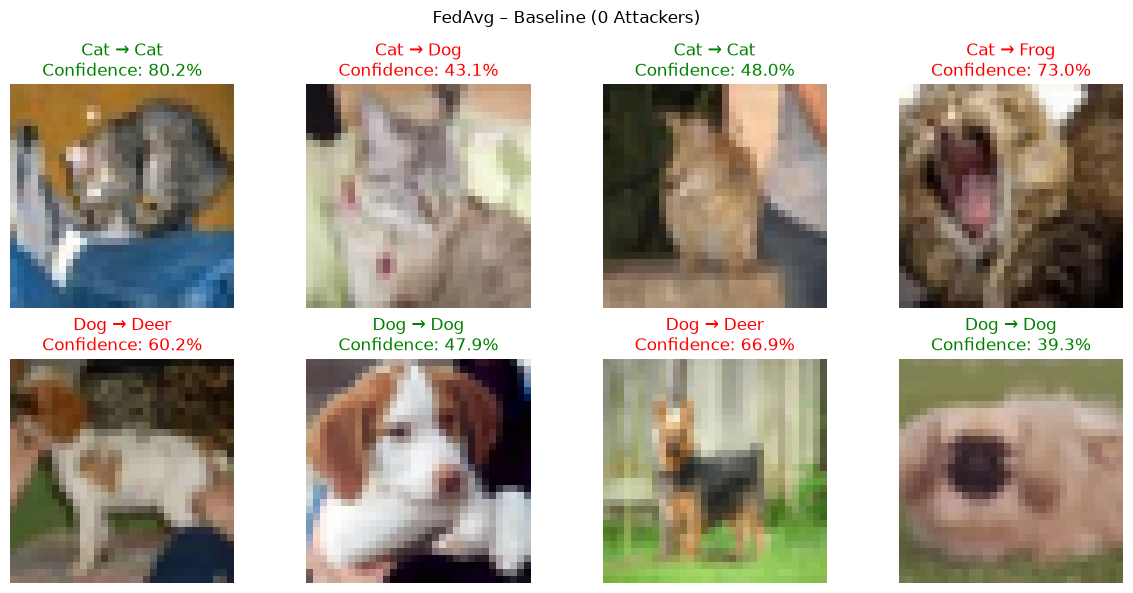

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from pytorchexample.task import load_centralized_dataset

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

# Select trained baseline model (0 attackers)
model = models_unprotected["0-attacker"]

if model is None:
    raise RuntimeError("Baseline model is not loaded.")

model.eval()

# Use centralized test dataset
testloader = load_centralized_dataset()

samples = {3: [], 5: []}

# Collect four cats and four dogs
for batch in testloader:
    images = batch["img"]
    labels = batch["label"]

    for image, label in zip(images, labels):
        label = int(label)

        if label in samples and len(samples[label]) < 4:
            samples[label].append((image, label))

    if all(len(v) == 4 for v in samples.values()):
        break

# Run predictions
selected_samples = samples[3] + samples[5]
images = torch.stack([image for image, _ in selected_samples])

with torch.no_grad():
    outputs = model(images)
    probabilities = torch.softmax(outputs, dim=1)
    confidence, predictions = probabilities.max(dim=1)

# Visualize
fig, axs = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axs.flat):
    image, true_label = selected_samples[i]

    predicted_label = int(predictions[i])
    conf = float(confidence[i])

    image = image.permute(1, 2, 0).numpy()
    image = np.clip(image / 2 + 0.5, 0, 1)

    ax.imshow(image)

    ax.set_title(
        f"{class_names[true_label]} → {class_names[predicted_label]}\n"
        f"Confidence: {conf:.1%}",
        color="green" if true_label == predicted_label else "red"
    )

    ax.axis("off")

plt.suptitle("FedAvg – Baseline (0 Attackers)")
plt.tight_layout()
plt.show()

In [6]:
# import matplotlib.pyplot as plt
# import numpy as np

# class_names = [
#     "Airplane", "Automobile", "Bird", "Cat", "Deer",
#     "Dog", "Frog", "Horse", "Ship", "Truck"
# ]


# samples = {3: [], 5: []}

# # Collect four cats and four dogs
# for batch in trainloader:
#     images = batch["img"]
#     labels = batch["label"]

#     for image, label in zip(images, labels):
#         label = int(label)

#         if label in samples and len(samples[label]) < 4:
#             samples[label].append((image, label))

#     if all(len(v) == 4 for v in samples.values()):
#         break

# # Visualize
# fig, axs = plt.subplots(2, 4, figsize=(12, 6))

# for row, class_id in enumerate([3, 5]):
#     for col, (image, label) in enumerate(samples[class_id]):

#         image = image.permute(1, 2, 0).numpy()
#         image = np.clip(image / 2 + 0.5, 0, 1)

#         # Current attack: cyclic label flipping
#         # attacked_label = (label + 1) % 10
#         attacked_label = 5 if label == 3 else label

#         ax = axs[row, col]
#         ax.imshow(image)
#         ax.set_title(
#             f"{class_names[label]} → {class_names[attacked_label]}"
#         )
#         ax.axis("off")

# plt.suptitle("Label Flipping Attack – Malicious Client")
# plt.tight_layout()
# plt.show()

In [7]:
# for attackers in range(4):
#     name = experiment_name("fedavg", attackers)

#     model_path = MODELS_DIR / f"{name}.pt"
#     metrics_path = RESULTS_DIR / f"{name}.json"

#     print("ModelPath ", model_path)

#     print(f"\n{name}")
#     print("Model exists:", model_path.is_file())
#     print("JSON exists: ", metrics_path.is_file())
#     print("Model path:", model_path)
#     print("JSON path: ", metrics_path)
name = experiment_name(0, "fedavg")

model_path = MODELS_DIR / f"{name}.pt"
metrics_path = RESULTS_DIR / f"{name}.json"

print("Experiment:", name)
print("Model path:", model_path)
print("Model exists:", model_path.is_file())
print()
print("JSON path:", metrics_path)
print("JSON exists:", metrics_path.is_file())

Experiment: fedavg_attack0_rounds35
Model path: C:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\Part_2-Federated Learning\modeller\fedavg_attack0_rounds35.pt
Model exists: True

JSON path: C:\Users\rasmu\OneDrive - BTH Student\Documents\PythonProjects\year4\AI-Security--DV2607\Assignment\Part_2-Federated Learning\resultat\fedavg_attack0_rounds35.json
JSON exists: True


In [8]:
# model, metrics = load_or_train("fedavg", 0)

# print("Model loaded:", isinstance(model, Net))
# print("Available rounds:", list(metrics.keys()))
# print("Final F1:", metrics["35"]["f1"])